<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/main/deep_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/train.csv')

# Display the first 5 rows
df.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [3]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()


Dataset Shape: (188533, 13)

Column Names:
['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memor

In [5]:
# Check missing values
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

# Display columns that contain missing values
missing_data = missing_data[missing_data['Missing Values'] > 0]

print("Missing Values Summary:")
display(missing_data)

# Check duplicate rows
print("                        ")
print("Number of Duplicate Rows:", df.duplicated().sum())


Missing Values Summary:


,Missing Values,Missing Percentage
fuel_type,5083,2.70
accident,2452,1.30
clean_title,21419,11.36


                        
Number of Duplicate Rows: 0


In [6]:
# Statistical summary of the target variable
print("Price Statistics:")
display(df['price'].describe())

# Check the number of unique prices
print("Unique Price Values:", df['price'].nunique())

Price Statistics:


,price
count,1.885330e+05
mean,4.387802e+04
std,7.881952e+04
min,2.000000e+03
25%,1.700000e+04
50%,3.082500e+04
75%,4.990000e+04
max,2.954083e+06


Unique Price Values: 1569


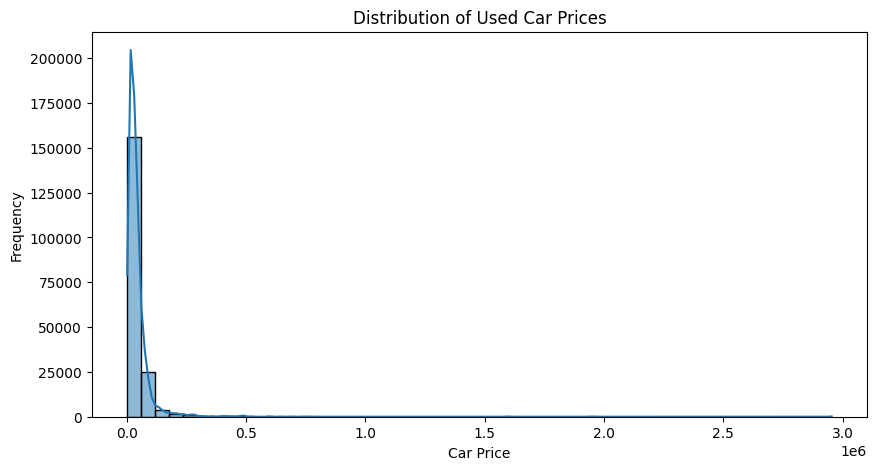

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='price', bins=50, kde=True)

plt.title('Distribution of Used Car Prices')
plt.xlabel('Car Price')
plt.ylabel('Frequency')

plt.show()

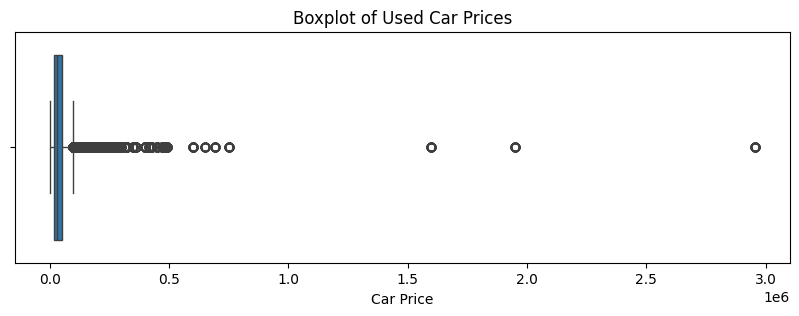

In [8]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=df['price'])

plt.title('Boxplot of Used Car Prices')
plt.xlabel('Car Price')

plt.show()


In [9]:
# Analyze numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nNumerical Features Statistics:")
display(df[numerical_cols].describe())

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Numerical Features Statistics:


,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


In [10]:

# Analyze categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")
print(categorical_cols.tolist())

# Count unique values in each categorical column
for col in categorical_cols:
    print(f"\n{col}:")
    print("Unique Values:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(10))

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

brand:
Unique Values: 57


,count
brand,
Ford,23088
Mercedes-Benz,19172
BMW,17028
Chevrolet,16335
Audi,10887
Porsche,10612
Land,9525
Toyota,8850
Lexus,8643



model:
Unique Values: 1897


,count
model,
F-150 XLT,2945
M3 Base,2229
Camaro 2SS,1709
M4 Base,1622
Mustang GT Premium,1526
F-150 Lariat,1410
E-Class E 350 4MATIC,1357
1500 Laramie,1249
911 Carrera S,1219



fuel_type:
Unique Values: 7


,count
fuel_type,
Gasoline,165940
Hybrid,6832
E85 Flex Fuel,5406
NaN,5083
Diesel,3955
–,781
Plug-In Hybrid,521
not supported,15


... (8 outputs left out)


accident:
Unique Values: 2


,count
accident,
None reported,144514
At least 1 accident or damage reported,41567
NaN,2452



clean_title:
Unique Values: 1


,count
clean_title,
Yes,167114
NaN,21419


In [11]:

print("Total ID values:", df['id'].nunique())
print("Total Rows:", len(df))

print("\nFirst 10 IDs:")
print(df['id'].head(10).tolist())

Total ID values: 188533
Total Rows: 188533

First 10 IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [12]:

# Check the actual values in clean_title
print("Clean Title Values:")
display(df['clean_title'].value_counts(dropna=False))

# Check special placeholder values
categorical_cols = df.select_dtypes(include=['object']).columns

print("\nSpecial Values in Categorical Columns:")

for col in categorical_cols:
    values = df[col].astype('string').str.strip().str.lower()

    dash_count = (values == '-').sum()
    unsupported_count = (values == 'not supported').sum()
    empty_count = (values == '').sum()

    if dash_count > 0 or unsupported_count > 0 or empty_count > 0:
        print(f"\nColumn: {col}")
        print("Dash (-):", dash_count)
        print("Not Supported:", unsupported_count)
        print("Empty Strings:", empty_count)

Clean Title Values:


,count
clean_title,
Yes,167114
NaN,21419



Special Values in Categorical Columns:

Column: fuel_type
Dash (-): 0
Not Supported: 15
Empty Strings: 0


In [13]:
# Check the number of unique values in each column

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")

# Inspect fuel_type values
print("\nFuel Type Values:")
display(df['fuel_type'].value_counts(dropna=False))

# Inspect clean_title values
print("\nClean Title Values:")
display(df['clean_title'].value_counts(dropna=False))


brand: 57 unique values
model: 1897 unique values
fuel_type: 7 unique values
engine: 1117 unique values
transmission: 52 unique values
ext_col: 319 unique values
int_col: 156 unique values
accident: 2 unique values
clean_title: 1 unique values

Fuel Type Values:


,count
fuel_type,
Gasoline,165940
Hybrid,6832
E85 Flex Fuel,5406
NaN,5083
Diesel,3955
–,781
Plug-In Hybrid,521
not supported,15



Clean Title Values:


,count
clean_title,
Yes,167114
NaN,21419


In [14]:
# Check different types of placeholder values

for col in categorical_cols:

    values = df[col].astype('string').str.strip()

    # Detect different dash symbols
    dash_mask = values.str.fullmatch(
        r'[-\u2010-\u2015\u2212]+',
        na=False
    )

    # Detect "not supported"
    unsupported_mask = (
        values.str.lower() == 'not supported'
    ).fillna(False)

    # Detect empty strings
    empty_mask = (values == '').fillna(False)

    if dash_mask.any() or unsupported_mask.any() or empty_mask.any():

        print(f"\nColumn: {col}")

        print("Dash values:")
        print(values[dash_mask].value_counts().to_dict())

        print("Not supported:",
              unsupported_mask.sum())

        print("Empty strings:",
              empty_mask.sum())


Column: fuel_type
Dash values:
{'–': 781}
Not supported: 15
Empty strings: 0

Column: engine
Dash values:
{'–': 925}
Not supported: 0
Empty strings: 0

Column: transmission
Dash values:
{'–': 87}
Not supported: 0
Empty strings: 0

Column: ext_col
Dash values:
{'–': 366}
Not supported: 0
Empty strings: 0

Column: int_col
Dash values:
{'–': 4527}
Not supported: 0
Empty strings: 0


In [15]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove unnecessary columns
df_clean = df_clean.drop(columns=['id', 'clean_title'])

# Replace placeholder values with missing values
placeholder_values = [
    '-',
    '–',
    '—',
    '−',
    'not supported'
]

for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].replace(
        placeholder_values, np.nan
    )

# Check the new dataset
print("New Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
display(df_clean.isnull().sum())

New Dataset Shape: (188533, 11)

Missing Values After Cleaning:


,0
brand,0
model,0
model_year,0
milage,0
fuel_type,5879
engine,925
transmission,87
ext_col,366
int_col,4527
accident,2452


In [16]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# First split: 70% Training and 30% Temporary
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42
)

# Second split: 15% Validation and 15% Testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

# Display the results
print("Training Set:", train_df.shape)
print("Validation Set:", val_df.shape)
print("Test Set:", test_df.shape)

print("\nTotal Records:",
      len(train_df) + len(val_df) + len(test_df))

Training Set: (131973, 11)
Validation Set: (28280, 11)
Test Set: (28280, 11)

Total Records: 188533


In [17]:

# Separate Features (X) and Target (y)

X_train = train_df.drop(columns=['price'])
y_train = train_df['price']

X_val = val_df.drop(columns=['price'])
y_val = val_df['price']

X_test = test_df.drop(columns=['price'])
y_test = test_df['price']

# Check the shapes
print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("Validation Features:", X_val.shape)
print("Validation Target:", y_val.shape)

print("Test Features:", X_test.shape)
print("Test Target:", y_test.shape)


Training Features: (131973, 10)
Training Target: (131973,)
Validation Features: (28280, 10)
Validation Target: (28280,)
Test Features: (28280, 10)
Test Target: (28280,)


In [18]:

from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Features:", num_cols)
print("Categorical Features:", cat_cols)

# Create imputers
num_imputer = SimpleImputer(strategy='median')

cat_imputer = SimpleImputer(
    strategy='constant',
    fill_value='Unknown'
)

# Fit on Training Data ONLY
X_train[num_cols] = num_imputer.fit_transform(
    X_train[num_cols]
)

X_train[cat_cols] = cat_imputer.fit_transform(
    X_train[cat_cols]
)

# Apply the same imputers to Validation and Test
X_val[num_cols] = num_imputer.transform(
    X_val[num_cols]
)

X_val[cat_cols] = cat_imputer.transform(
    X_val[cat_cols]
)

X_test[num_cols] = num_imputer.transform(
    X_test[num_cols]
)

X_test[cat_cols] = cat_imputer.transform(
    X_test[cat_cols]
)

# Check remaining missing values
print("\nMissing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Validation:", X_val.isnull().sum().sum())
print("Missing Values in Test:", X_test.isnull().sum().sum())


Numerical Features: ['model_year', 'milage']
Categorical Features: ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident']

Missing Values in Training: 0
Missing Values in Validation: 0
Missing Values in Test: 0


In [19]:

# Step 12: Categorical Encoding

# Create a dictionary to store category mappings
category_maps = {}

# Learn category mappings from Training Data ONLY
for col in cat_cols:

    categories = sorted(X_train[col].astype(str).unique())

    # Start IDs from 1 (0 is reserved for unseen categories)
    category_maps[col] = {
        category: idx + 1
        for idx, category in enumerate(categories)
    }

    # Encode Training Data
    X_train[col] = (
        X_train[col].astype(str)
        .map(category_maps[col])
        .astype('int64')
    )

    # Encode Validation Data
    X_val[col] = (
        X_val[col].astype(str)
        .map(category_maps[col])
        .fillna(0)
        .astype('int64')
    )

    # Encode Test Data
    X_test[col] = (
        X_test[col].astype(str)
        .map(category_maps[col])
        .fillna(0)
        .astype('int64')
    )

# Display the results
print("Categorical Encoding Completed!")

print("\nEncoded Training Features:")
display(X_train[cat_cols].head())

print("\nNumber of Categories:")
for col in cat_cols:
    print(col, ":", len(category_maps[col]))

# Check data types
print("\nData Types:")
print(X_train.dtypes)


Categorical Encoding Completed!

Encoded Training Features:


,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident
69007,54,85,3,343,39,306,15,1
68561,28,793,3,808,18,264,123,2
22502,4,191,3,608,39,264,15,2
4493,11,20,2,493,39,264,72,1
32131,32,518,3,144,21,306,15,2



Number of Categories:
brand : 57
model : 1896
fuel_type : 6
engine : 1112
transmission : 52
ext_col : 319
int_col : 156
accident : 3

Data Types:
brand             int64
model             int64
model_year      float64
milage          float64
fuel_type         int64
engine            int64
transmission      int64
ext_col           int64
int_col           int64
accident          int64
dtype: object


In [20]:

# Step 13: Numerical Feature Scaling

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on Training Data ONLY
X_train[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

# Apply the same scaler to Validation and Test
X_val[num_cols] = scaler.transform(
    X_val[num_cols]
)

X_test[num_cols] = scaler.transform(
    X_test[num_cols]
)

# Check the results
print("Scaled Training Features:")
display(X_train[num_cols].describe().round(3))

print("\nValidation Features:")
display(X_val[num_cols].describe().round(3))

print("\nTest Features:")
display(X_test[num_cols].describe().round(3))


Scaled Training Features:


,model_year,milage
count,131973.000,131973.000
mean,0.000,0.000
std,1.000,1.000
min,-7.389,-1.319
25%,-0.498,-0.832
50%,0.208,-0.161
75%,0.738,0.595
max,1.445,6.811



Validation Features:


,model_year,milage
count,28280.000,28280.000
mean,0.002,-0.009
std,1.004,0.993
min,-7.389,-1.319
25%,-0.498,-0.841
50%,0.208,-0.161
75%,0.738,0.586
max,1.445,6.811



Test Features:


,model_year,milage
count,28280.000,28280.000
mean,0.008,-0.004
std,0.998,1.006
min,-4.209,-1.319
25%,-0.498,-0.847
50%,0.208,-0.168
75%,0.738,0.586
max,1.445,6.811


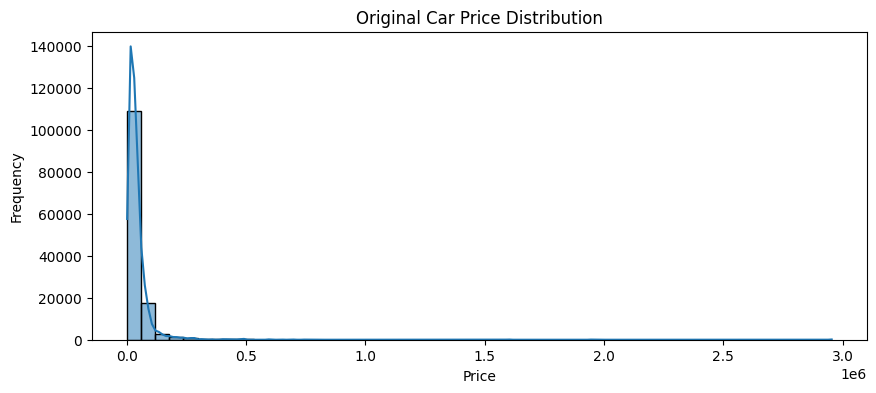

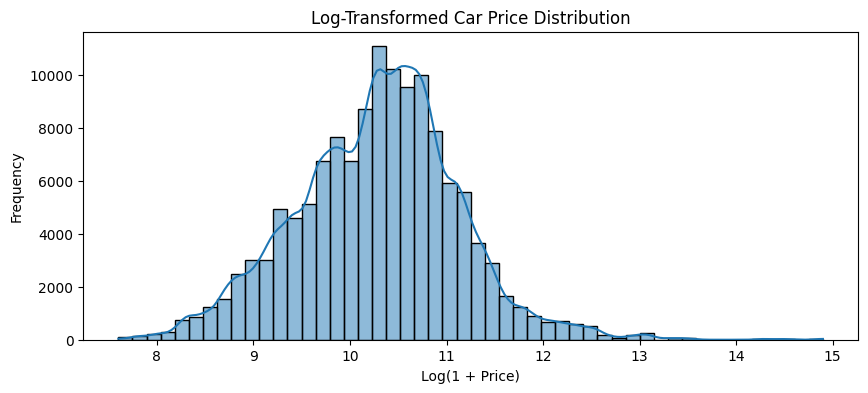

Original Price Skewness: 20.64781154347407
Log-Transformed Price Skewness: 0.11052380058717097


In [21]:

# Step 14: Analyze Target Transformation

# Original target distribution
plt.figure(figsize=(10, 4))

sns.histplot(y_train, bins=50, kde=True)

plt.title('Original Car Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()


# Log-transformed target distribution
y_train_log = np.log1p(y_train)

plt.figure(figsize=(10, 4))

sns.histplot(y_train_log, bins=50, kde=True)

plt.title('Log-Transformed Car Price Distribution')
plt.xlabel('Log(1 + Price)')
plt.ylabel('Frequency')

plt.show()


# Compare skewness
print("Original Price Skewness:",
      y_train.skew())

print("Log-Transformed Price Skewness:",
      y_train_log.skew())


In [22]:
print("Original Price Skewness:", y_train.skew())

print("Log-Transformed Price Skewness:", y_train_log.skew())


Original Price Skewness: 20.64781154347407
Log-Transformed Price Skewness: 0.11052380058717097


In [23]:

# Step 15: Apply Log Transformation to all targets

# Preserve original prices
y_train_original = y_train.copy()
y_val_original = y_val.copy()
y_test_original = y_test.copy()

# Apply Log Transformation
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

# Check the results
print("Training Target:")
print("Original:", y_train_original.head().tolist())
print("Transformed:", y_train_log.head().tolist())

print("\nValidation Target Shape:", y_val_log.shape)
print("Test Target Shape:", y_test_log.shape)

print("\nTransformed Training Skewness:",
      y_train_log.skew())


Training Target:
Original: [12900, 69685, 42500, 16900, 13700]
Transformed: [9.465060106725137, 11.151754715741239, 10.657282884047461, 9.735128070758227, 9.525224101853109]

Validation Target Shape: (28280,)
Test Target Shape: (28280,)

Transformed Training Skewness: 0.11052380058717097
